<a href="https://colab.research.google.com/github/PranavSuresh525/Optimization-Course-Project/blob/main/Optimization_Course_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import numpy as np
import pyomo.environ as pyo
def generate_scenarios(t_hours, wind_rated, rho, sigma, seed, n_raw=100):# used to generate the monte carlo simulations
    rng = np.random.default_rng(seed)
    eps = rng.standard_normal((t_hours, n_raw))
    xi = np.zeros((t_hours, n_raw))
    xi[0, :] = sigma * eps[0, :]

    for t in range(1, t_hours):
        xi[t, :] = rho * xi[t-1, :] + math.sqrt(1.0 - rho**2) * sigma * eps[t, :]

    # Sort paths by total wind energy across the week
    total_energy = np.sum(xi, axis=0)
    sorted_indices = np.argsort(total_energy)

    # Extract 5 representative percentile paths
    percentiles = [10, 30, 50, 70, 90]
    selected_indices = [sorted_indices[int(p * n_raw / 100)] for p in percentiles]

    W_TW = {}
    for w, idx in enumerate(selected_indices):
        for t in range(t_hours):
            h = t % 24
            # Baseline wind forecast
            cf = 0.5 + 0.20 * math.sin(2 * math.pi * (h - 6) / 24) + 0.15 * math.sin(2 * math.pi * (t + 1) / 61.0)
            base_wind = wind_rated * min(0.85, max(0.15, cf))
            W_TW[(t + 1, w)] = float(np.clip(base_wind + xi[t, idx], 0.0, wind_rated)) # makes sure the forcast doesnt cross a certain threshold

    return W_TW # final wind values used for problem for each time stamp

 # define the function for the main model
def run_stochastic_maintenance(inputs: dict) -> dict:
# store the inputs in respective variables
    T_HOURS    = inputs.get("T_HOURS", 168)
    M_MAX      = inputs.get("M_MAX", 1)
    THETA_BAR  = inputs.get("THETA_BAR", 0.5)
    C_CURT     = inputs.get("C_CURT", 5.0)
    C_SHED     = inputs.get("C_SHED", 1000.0)

    buses      = inputs["buses"]
    gens       = inputs["gens"]
    lines      = inputs["lines"]
    maint      = inputs["maint"]
    W_TW       = inputs["W_TW"]
    scen_probs = inputs["scenario_probs"]

    # Derived network parameter
    B_l = {l: 100.0 / lines[l][2] for l in lines} # line suseptance ( base susaptance set as 100MVA)
    F_l = {l: float(lines[l][3]) for l in lines} # maximum power that can flow in lines
    M_l = {l: B_l[l] * 2 * THETA_BAR + F_l[l] for l in lines} # 'Big M' derived for relaxation problem

    def load_mw(b, t):   # function to simulate the load demands by customer
        h = (t - 1) % 24
        shape = 0.65 if h <= 7 else (0.85 if h <= 17 else (1.00 if h <= 21 else 0.85))
        return buses[b] * shape * (0.8 if t >= 121 else 1.0)

    def maint_cost(m, t): # gives different values for maintanence based on keeday or weekend
        return maint[m]["c_we"] if t >= 121 else maint[m]["c_wd"]

    # Initialize Pyomo Model
    mdl = pyo.ConcreteModel()

    mdl.T  = pyo.RangeSet(1, T_HOURS)
    mdl.B  = pyo.Set(initialize=sorted(buses.keys()))
    mdl.G  = pyo.Set(initialize=list(gens.keys()))
    mdl.L  = pyo.Set(initialize=list(lines.keys()))
    mdl.M  = pyo.Set(initialize=list(maint.keys()))
    mdl.Lf = pyo.Set(initialize=[l for l in lines if l not in maint])
    mdl.W  = pyo.RangeSet(0, len(scen_probs) - 1)

    # Variables
    mdl.s     = pyo.Var(mdl.M, mdl.T, within=pyo.Binary)
    mdl.x     = pyo.Var(mdl.M, mdl.T, within=pyo.Binary)
    mdl.pg    = pyo.Var(mdl.G, mdl.T, mdl.W, within=pyo.NonNegativeReals)
    mdl.curt  = pyo.Var(mdl.T, mdl.W, within=pyo.NonNegativeReals)
    mdl.shed  = pyo.Var(mdl.B, mdl.T, mdl.W, within=pyo.NonNegativeReals)
    mdl.theta = pyo.Var(mdl.B, mdl.T, mdl.W, bounds=(-THETA_BAR, THETA_BAR))
    mdl.f     = pyo.Var(mdl.L, mdl.T, mdl.W, within=pyo.Reals)

    # Objective
    mdl.OBJ = pyo.Objective(
        expr = 1000.0 * sum(maint_cost(mm, t) * mdl.x[mm, t] for mm in mdl.M for t in mdl.T) +
               sum(scen_probs[w] * (
                   sum(gens[g][2] * mdl.pg[g, t, w] for g in mdl.G) +
                   C_CURT * mdl.curt[t, w] +
                   C_SHED * sum(mdl.shed[b, t, w] for b in mdl.B)
               ) for w in mdl.W for t in mdl.T),
        sense=pyo.minimize
    )

    # Stage 1 Constraints
    # C_S2- Single Start Time constraints
    mdl.C_S2 = pyo.Constraint(mdl.M, rule=lambda m, mm: sum(m.s[mm, t] for t in range(maint[mm]["tmin"], maint[mm]["tmax"] + 1)) == 1)
    # CS_3- Time Window Enforcement constraints
    mdl.C_S3 = pyo.Constraint(mdl.M, mdl.T, rule=lambda m, mm, t: m.s[mm, t] == 0 if t < maint[mm]["tmin"] or t > maint[mm]["tmax"] else pyo.Constraint.Skip)
    # CS_4- Contiguous Duration constrinats
    mdl.C_S4 = pyo.Constraint(mdl.M, mdl.T, rule=lambda m, mm, t: m.x[mm, t] == sum(m.s[mm, tau] for tau in range(max(1, t - maint[mm]["D"] + 1), t + 1)))
    # CS_5- Simultaneous Crew Limit constraints
    mdl.C_S5 = pyo.Constraint(mdl.T, rule=lambda m, t: sum(m.x[mm, t] for mm in m.M) <= M_MAX)

    # Stage 2 Constraints
    dth = lambda m, l, t, w: m.theta[lines[l][0], t, w] - m.theta[lines[l][1], t, w]

    # DC Power Flow ( Fixed Lines) constraints
    mdl.C_S6  = pyo.Constraint(mdl.Lf, mdl.T, mdl.W, rule=lambda m, l, t, w: m.f[l, t, w] == B_l[l] * dth(m, l, t, w))
    # Thermal Limits (Fixed Lines) constraints
    mdl.C_S7  = pyo.Constraint(mdl.Lf, mdl.T, mdl.W, rule=lambda m, l, t, w: pyo.inequality(-F_l[l], m.f[l, t, w], F_l[l]))
    # Switched Power Flow (Big-M) constraints
    mdl.C_S8a = pyo.Constraint(mdl.M, mdl.T, mdl.W, rule=lambda m, mm, t, w: m.f[mm, t, w] - B_l[mm] * dth(m, mm, t, w) <= M_l[mm] * m.x[mm, t])
    mdl.C_S8b = pyo.Constraint(mdl.M, mdl.T, mdl.W, rule=lambda m, mm, t, w: m.f[mm, t, w] - B_l[mm] * dth(m, mm, t, w) >= -M_l[mm] * m.x[mm, t])
    # Switched Thermal Limits constraints
    mdl.C_S9a = pyo.Constraint(mdl.M, mdl.T, mdl.W, rule=lambda m, mm, t, w: m.f[mm, t, w] <= F_l[mm] * (1 - m.x[mm, t]))
    mdl.C_S9b = pyo.Constraint(mdl.M, mdl.T, mdl.W, rule=lambda m, mm, t, w: m.f[mm, t, w] >= -F_l[mm] * (1 - m.x[mm, t]))

    def c_s10(m, b, t, w):
        gen = sum(m.pg[g, t, w] for g in m.G if gens[g][0] == b)
        wind_inj = (W_TW[(t, w)] - m.curt[t, w]) if b == 1 else 0.0
        out_f = sum(m.f[l, t, w] for l in m.L if lines[l][0] == b)
        in_f  = sum(m.f[l, t, w] for l in m.L if lines[l][1] == b)
        return gen + wind_inj + m.shed[b, t, w] == load_mw(b, t) + out_f - in_f
    # Nodal Power Balance equation
    mdl.C_S10 = pyo.Constraint(mdl.B, mdl.T, mdl.W, rule=c_s10)
    # Generator Capacity constriant
    mdl.C_S11 = pyo.Constraint(mdl.G, mdl.T, mdl.W, rule=lambda m, g, t, w: m.pg[g, t, w] <= gens[g][1])
    # Logical Curtailment
    mdl.C_S12 = pyo.Constraint(mdl.T, mdl.W, rule=lambda m, t, w: m.curt[t, w] <= W_TW[(t, w)])
    # Logical Load Shedding constraint
    mdl.C_S13 = pyo.Constraint(mdl.B, mdl.T, mdl.W, rule=lambda m, b, t, w: m.shed[b, t, w] <= load_mw(b, t))
    # Slack Bus Reference constraint
    mdl.C_S14 = pyo.Constraint(mdl.T, mdl.W, rule=lambda m, t, w: m.theta[1, t, w] == 0)

    # Solve the equations
    solver = pyo.SolverFactory(inputs.get("solver", "appsi_highs"))
    if hasattr(solver.config, 'mip_gap'):
        solver.config.mip_gap = inputs.get("mip_gap", 0.01)
    if hasattr(solver.config, 'time_limit'):
        solver.config.time_limit = inputs.get("time_limit", 600)

    res = solver.solve(mdl)


    pv = pyo.value

    # store the results in systematic order with variables and names
    maint_schedule = {}
    for mm in mdl.M:
        start_time = next((t for t in mdl.T if round(pv(mdl.s[mm, t])) == 1), None)
        if start_time is not None:
            maint_schedule[mm] = {
                "start_hour": start_time,
                "end_hour": start_time + maint[mm]["D"] - 1,
                "binary_matrix": [round(pv(mdl.x[mm, t])) for t in mdl.T]
            }

    maint_total = 1000.0 * sum(maint_cost(mm, t) * pv(mdl.x[mm, t]) for mm in mdl.M for t in mdl.T)
    expected_dispatch_cost = pv(mdl.OBJ) - maint_total

    outputs = {
        "status": res.solver.status,
        "termination_condition": res.solver.termination_condition,
        "objective_value": pv(mdl.OBJ),
        "maintenance_cost": maint_total,
        "expected_dispatch_cost": expected_dispatch_cost,
        "maintenance_schedule": maint_schedule,
        "model": mdl
    }

    return outputs


if __name__ == "__main__":
    # Generate Wind Scenarios
    WIND_RATED = 300.0
    W_TW_scenarios = generate_scenarios(
        t_hours=168, wind_rated=WIND_RATED, rho=0.92,
        sigma=(0.15 * WIND_RATED), seed=42
    )

    # Compile Inputs
    model_inputs = {
        "T_HOURS": 168,
        "M_MAX": 1,
        "THETA_BAR": 0.5,
        "C_CURT": 5.0,
        "C_SHED": 1000.0,
        "WIND_RATED": WIND_RATED,
        "solver": "appsi_highs",
        "mip_gap": 0.01,
        "time_limit": 600,

        "scenario_probs": {0: 0.10, 1: 0.20, 2: 0.40, 3: 0.20, 4: 0.10},
        "W_TW": W_TW_scenarios,

        "buses": {1: 0, 2: 50, 3: 50, 4: 150, 5: 150, 6: 100},
        "gens": {"G2": (2, 200, 30), "G4": (4, 250, 50), "G6": (6, 150, 70)},
        "lines": {
            "L12": (1, 2, 0.10, 250), "L13": (1, 3, 0.12, 250), "L23": (2, 3, 0.10, 200),
            "T-A": (2, 4, 0.15, 120), "T-B": (3, 5, 0.15, 120), "T-C": (3, 6, 0.20, 100),
            "L45": (4, 5, 0.10, 100), "L46": (4, 6, 0.12, 150), "L56": (5, 6, 0.10, 150),
        },
        "maint": {
            "T-A": dict(tmin=1,  tmax=96,  D=24, c_wd=1.0, c_we=1.1),
            "T-B": dict(tmin=1,  tmax=96,  D=24, c_wd=1.0, c_we=1.1),
            "T-C": dict(tmin=49, tmax=144, D=24, c_wd=1.0, c_we=1.1),
            "L45": dict(tmin=49, tmax=144, D=24, c_wd=0.8, c_we=0.9),
        }
    }

    # Solve and capture outputs
    results = run_stochastic_maintenance(model_inputs)

print(f"Total Cost: ${results['objective_value']}")
print(results['maintenance_schedule']['T-A'])

Total Cost: $1510775.993433005
{'start_hour': 96, 'end_hour': 119, 'binary_matrix': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


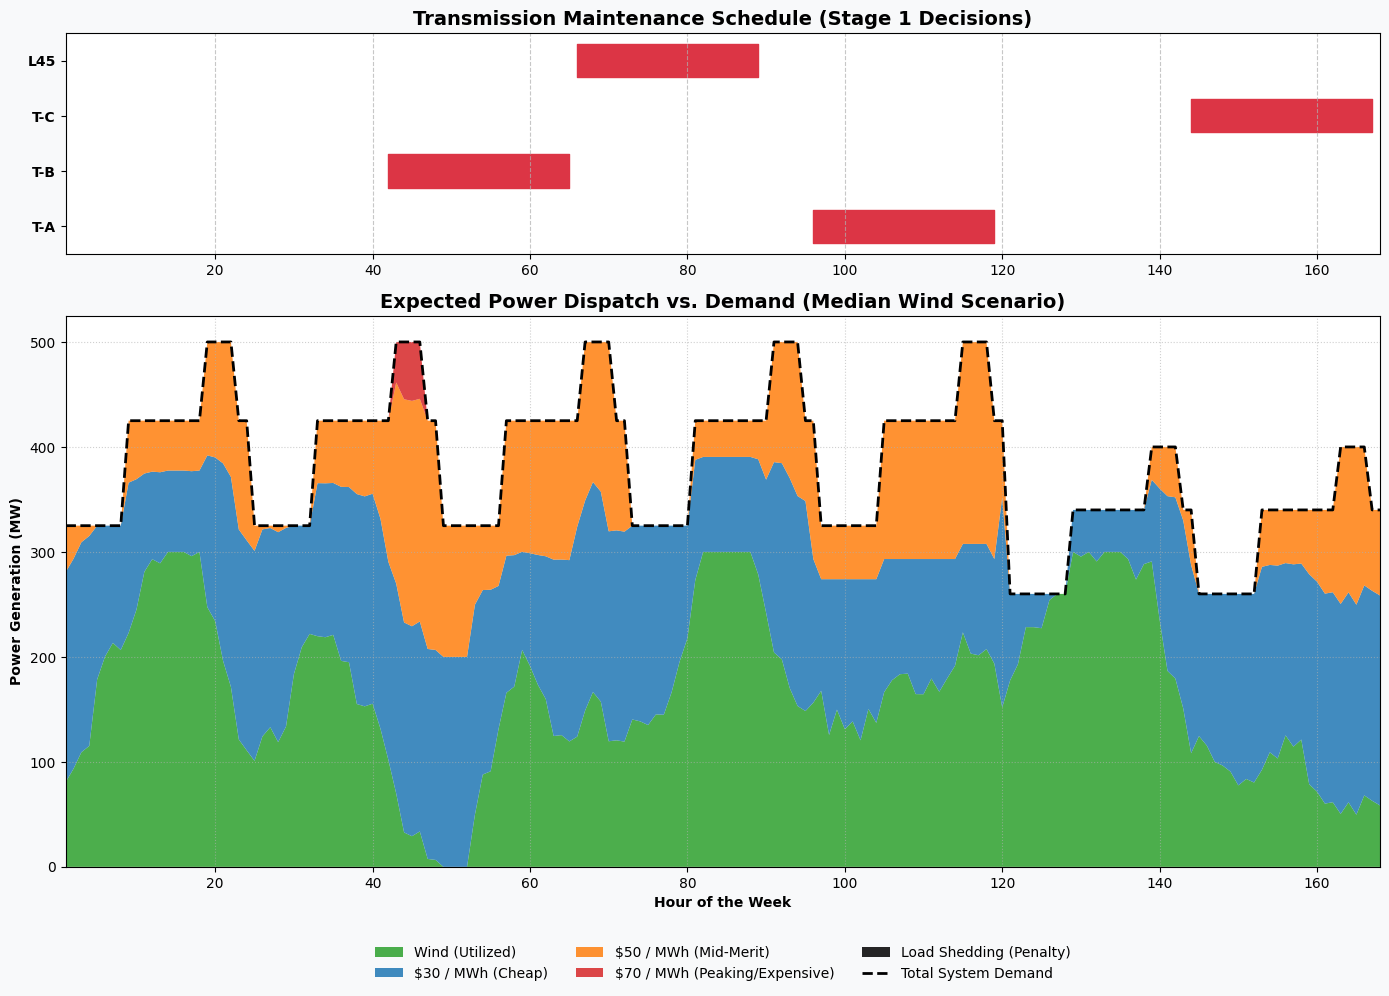

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo

def plot_executive_summary(results, inputs, scenario_w=2):
    """
    Plots the 2 most informative graphs in a single dashboard:
    1. The Stage 1 Maintenance Gantt Chart.
    2. The Stage 2 Dispatch Stack for a representative (Median) scenario.
    """
    mdl = results["model"]
    pv = pyo.value
    hours = list(mdl.T)

    # Set up the figure with 2 subplots (Dispatch chart gets more vertical space)
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [1, 2.5]})
    fig.patch.set_facecolor('#f8f9fa')

    # ==========================================
    # GRAPH 1: MAINTENANCE GANTT CHART
    # ==========================================
    ax1 = axes[0]
    maint_lines = list(mdl.M)

    for i, m in enumerate(maint_lines):
        x_vals = [pv(mdl.x[m, t]) for t in hours]
        # Fill between to create visual scheduling blocks
        ax1.fill_between(hours, i - 0.3, i + 0.3, where=[x > 0.5 for x in x_vals],
                         color='#dc3545', step='mid', label="Offline" if i==0 else "")

    ax1.set_yticks(range(len(maint_lines)))
    ax1.set_yticklabels(maint_lines, fontweight='bold')
    ax1.set_title("Transmission Maintenance Schedule (Stage 1 Decisions)", fontsize=14, fontweight='bold')
    ax1.grid(axis='x', linestyle='--', alpha=0.7)
    ax1.set_xlim(1, max(hours))
    ax1.set_ylim(-0.5, len(maint_lines) - 0.5)

    # ==========================================
    # GRAPH 2: DISPATCH STACKED AREA (Scenario 2)
    # ==========================================
    ax2 = axes[1]

    # Extract thermal generation
    gen_G2 = np.array([pv(mdl.pg["G2", t, scenario_w]) for t in hours])
    gen_G4 = np.array([pv(mdl.pg["G4", t, scenario_w]) for t in hours])
    gen_G6 = np.array([pv(mdl.pg["G6", t, scenario_w]) for t in hours])

    # Wind Used = Total Available Wind - Curtailed Wind
    wind_avail = np.array([inputs["W_TW"][(t, scenario_w)] for t in hours])
    wind_curt = np.array([pv(mdl.curt[t, scenario_w]) for t in hours])
    wind_used = wind_avail - wind_curt

    # Shedding (if any)
    shedding = np.array([sum(pv(mdl.shed[b, t, scenario_w]) for b in mdl.B) for t in hours])

    # Re-calculate true system load based on the mathematical shape
    def get_load(t):
        h = (t - 1) % 24
        shape = 0.65 if h <= 7 else (0.85 if h <= 17 else (1.00 if h <= 21 else 0.85))
        week_mod = 0.8 if t >= 121 else 1.0
        return sum(inputs["buses"][b] * shape * week_mod for b in mdl.B)

    total_load = [get_load(t) for t in hours]

    # Stackplot arrays and styling
    stacks = np.vstack([wind_used, gen_G2, gen_G4, gen_G6, shedding])
    labels = ["Wind (Utilized)", "$30 / MWh (Cheap)", "$50 / MWh (Mid-Merit)", "$70 / MWh (Peaking/Expensive)", "Load Shedding (Penalty)"]
    colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728", "#000000"]

    ax2.stackplot(hours, stacks, labels=labels, colors=colors, alpha=0.85)

    # Overlay the exact load requirement curve
    ax2.plot(hours, total_load, color='black', linewidth=2, linestyle='--', label="Total System Demand")

    # Formatting
    ax2.set_title("Expected Power Dispatch vs. Demand (Median Wind Scenario)", fontsize=14, fontweight='bold')
    ax2.set_ylabel("Power Generation (MW)", fontweight='bold')
    ax2.set_xlabel("Hour of the Week", fontweight='bold')
    ax2.set_xlim(1, max(hours))

    # Place legend cleanly outside the plot
    ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
    ax2.grid(linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_executive_summary(results, model_inputs, scenario_w=4)